# Original DINGO model: one starting fit → MCMC

Run this notebook from the **grism** Python kernel. It needs your source's `image.fits`, `R.fits`, `C.fits`, source metadata `config_kinematics.yaml`, and grism calibration tables. **No earlier search, PySersic fit, or saved kinematic run is required.** The functions live in `dingo/simple_mcmc.py`; their docstrings explain the settings.

We use one arctangent disk to rectify R and C, then compare those corrected images. Intrinsic dispersion is zero. The direct image is displayed for context; it is not imposed as the gas-emission shape.

$$V(r)=\frac{2}{\pi}V_\infty\arctan(r/R_t),\qquad v_{\rm los}=V(r)\sin i\cos\phi.$$

**The velocity here is always the deprojected asymptotic amplitude $V_\infty$**, not $V\sin i$ and not velocity at a particular radius. Radii and centers remain in stack pixels. The explicit inclination prior is your assumption, not a new imaging measurement.

In [1]:
from pathlib import Path
import os
import sys
import logging
import matplotlib.pyplot as plt
from IPython.display import display

# Change these paths on another computer. No saved fits are read from them.
REPO = Path("/home/aakavan/kinematics/grism-kinematics")
DATA_DIR = REPO / "data"
CALIBRATION_DIR = REPO.parent / "grism_cal"
OUTPUT_ROOT = REPO.parent / "field_kinematics/edr_kinematics/PaA/dingo_runs"

sys.path.insert(0, str(REPO))
os.environ["GRISM_CAL_DIR"] = str(CALIBRATION_DIR)
# Keep warnings visible; progress bars report the sampling steps.
logging.getLogger("dingo.fitting").setLevel(logging.WARNING)
from dingo import simple_mcmc as sm

print("Code:", sm.__file__)
print("Output root:", OUTPUT_ROOT)

Code: /home/aakavan/kinematics/grism-kinematics/dingo/simple_mcmc.py
Output root: /home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs


## 1. Choose the source, starting values, and inclination prior

All values for this experiment are in this call. `start_inclination` initializes the fit; `inclination_mean` and `inclination_sigma` define its Gaussian prior. Here 75° ± 5° is an **editable example assumption**. Use the inclination appropriate to your source.

For an 81×81 R/C cutout, the zero-based center is **(40, 40)**. `start_center=None` selects the cutout center automatically. `start_pa` is the existing DINGO cutout orientation, in degrees.

`overwrite=True` replaces only this named **simple_mcmc** experiment; it never touches your input FITS files or other runs. Use a different `run_name` to retain and compare another start.

ID6170: explicit V_inf=100 km/s, i=75 deg; prior i=75 +/- 5 deg.
Saving to /home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs/6170/simple_v100_i75


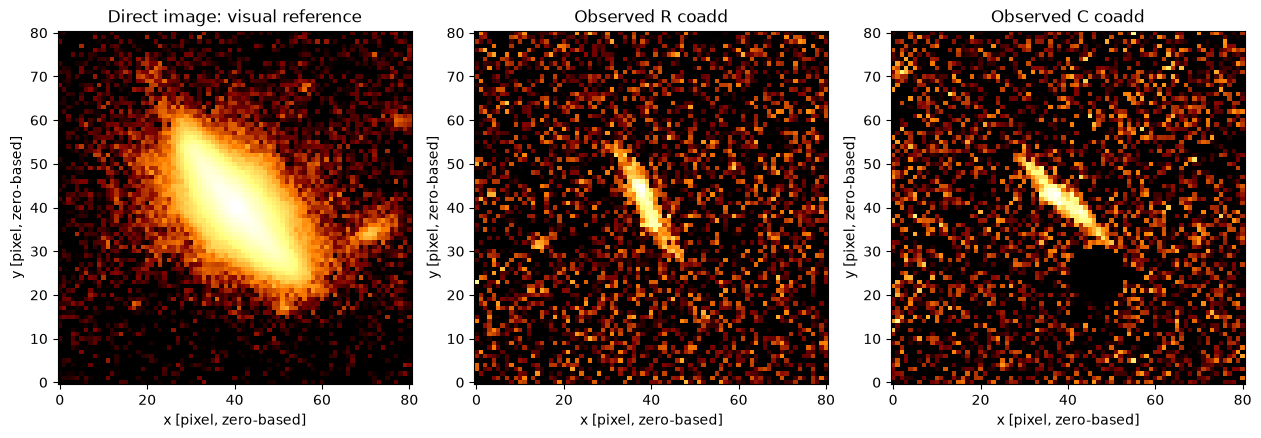

In [ ]:
run = sm.prepare(
    3700,
    data_dir=DATA_DIR,
    output_root=OUTPUT_ROOT,
    run_name="simple_v100_i75",
    overwrite=True,
    device="cuda",                   # "cpu" also works, more slowly
    start_velocity=100.0,            # V_inf, km/s
    start_inclination=75.0,          # initial i, degrees
    start_pa=0.0,                    # initial DINGO orientation, degrees
    start_turnover=3.0,              # R_t, pixels
    start_center=None,              # or (x0, y0), absolute zero-based pixels
    start_offset=(0.0, 0.0),         # R registration dx,dy, pixels
    inclination_mean=75.0,           # prior mean, degrees
    inclination_sigma=5.0,           # prior 1 sigma, degrees
    max_velocity=1000.0,
    noise_correlation_area=1.0,      # explicit fixed-noise approximation
)

fig = sm.show_inputs(run)
display(fig)
plt.close(fig)

## 2. Improve this one starting fit and inspect its residuals

This is a single **local Powell optimization**, using exactly the same log posterior as MCMC. There is no velocity grid and no hidden candidate selection. It can still find a local solution, and its evaluation limit is not a convergence guarantee. Skip the first line below if you want to sample directly from your explicit start.

The image panels are **corrected R, corrected C, and R−C**. The cross marks the fitted kinematic center. The first two panels share their color scale; the signed residual has a symmetric scale. Look for coherent residual structure and a plausible center before interpreting the velocity.

Local fit evaluations:   0%|          | 0/3000 [00:00<?, ?it/s]

Local fit: Optimization terminated successfully. (1390 evaluations).


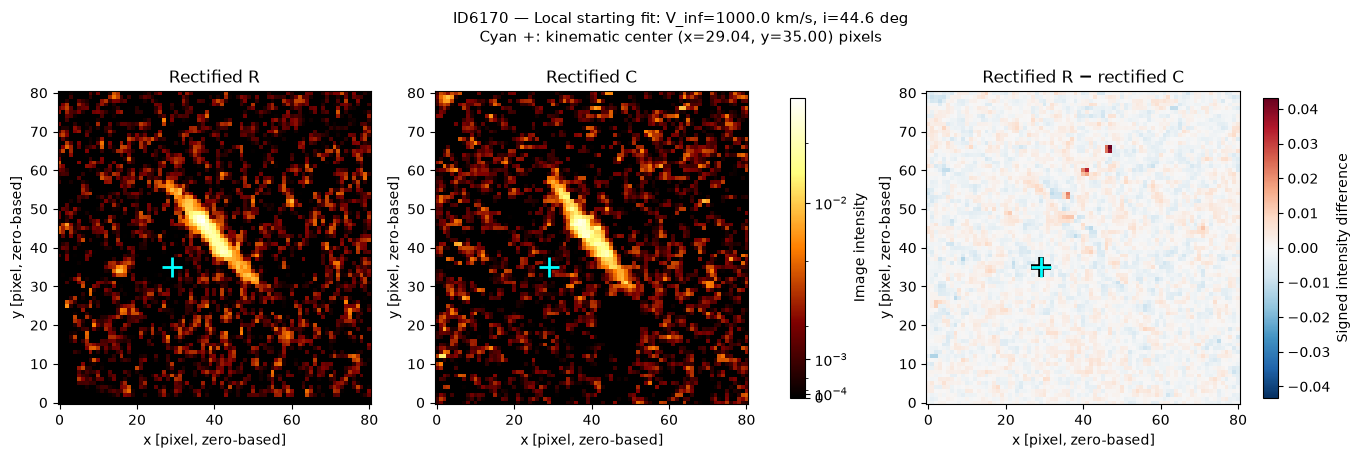

In [7]:
fit_status = sm.fit_local(run, max_evaluations=3000)
fig = sm.show_fit(run, label="Local starting fit")
display(fig)
fig.savefig(run.directory / "starting_fit.png", dpi=150, bbox_inches="tight")
plt.close(fig)

## 3. Run MCMC

The ensemble starts around the exact fit displayed above. Inclination, velocity, turnover radius, center, orientation, and the two R registration shifts are sampled. C registration and systemic velocity remain fixed. There is no dispersion parameter.

`warmup` is discarded; `draws` is retained **per walker**. For an execution check, try `warmup=100, draws=200, walkers=32`. The defaults below are an initial analysis run, **not a promise of convergence**. Walkers are members of one ensemble, not independent chains.

The sampler is **emcee**, with the PyTorch likelihood evaluated in GPU batches when `device="cuda"`. Progress bars show warmup and retained draws separately. A checkpoint is saved every 50 steps and on completion/interruption.

In [4]:
RESULT_DIR = sm.sample(
    run,
    warmup=1000,
    draws=4000,
    walkers=64,
    seed=42,
    progress="notebook",             # use True for a text bar if widgets are unavailable
)
print("Saved results:", RESULT_DIR)

Warmup:   0%|          | 0/1000 [00:00<?, ?it/s]

MCMC draws:   0%|          | 0/4000 [00:00<?, ?it/s]

The chain is shorter than 50 times the integrated autocorrelation time for 7 parameter(s). Use this estimate with caution and run a longer chain!
N/50 = 80;
tau: [ 90.53488057 220.34991579 132.21876577 247.35470157 177.59218826
 194.75099099 254.7017565   66.60910098]


finished: 4000 retained steps per walker.
Results: /home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs/6170/simple_v300_i75
Saved results: /home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs/6170/simple_v300_i75


## 4. Inspect the saved result

The table and black corner plot show **one pooled median and 16–84% interval**. The residual figure uses **one actual maximum-posterior sample** and prints that sample's velocity/inclination; it need not equal every marginal median. Traces show every walker. Stuck walkers, drift, or accumulation at a prior bound require further investigation; a finished run is not automatically a measurement.

This cell only reads saved files. After restarting the kernel, run the imports and this cell; set `RESULT_DIR` explicitly if needed. Do **not** rerun preparation with `overwrite=True` just to view results.

Status: finished; retained steps/walker: 4000; latest segment mean acceptance: 0.100
These are conditional posterior summaries. Check traces, bounds and independent starts before quoting errors.
Autocorrelation time per parameter: {'velocity.V_rot': 90.53488057271845, 'velocity.R_v': 220.34991579382162, 'velocity.x0_v': 132.2187657732923, 'velocity.y0_v': 247.3547015692068, 'velocity.theta_v': 177.5921882602734, 'velocity.inc_v': 194.75099099047233, 'image.R.dx': 254.70175650005265, 'image.R.dy': 66.60910097782542}


,median,minus_16th,plus_84th,unit
parameter (all walkers pooled),,,,
V_inf,988.162004,17.307226,8.764777,km/s
R_t,29.860780,1.141406,2.693226,pixel
x_center,33.335937,0.664458,0.532801,pixel
y_center,44.238005,1.193518,0.287937,pixel
cutout_PA,289.942973,0.491097,0.845783,deg
inclination,63.246489,2.577225,1.477682,deg
R_x_offset,-2.402563,0.097628,0.335944,pixel
R_y_offset,2.276803,0.015778,0.015831,pixel


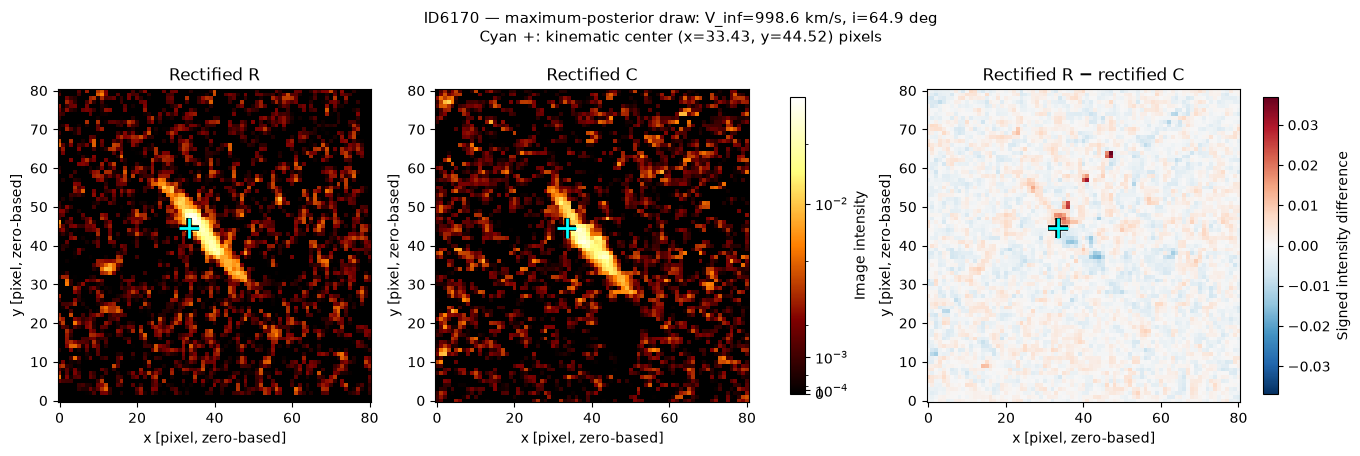

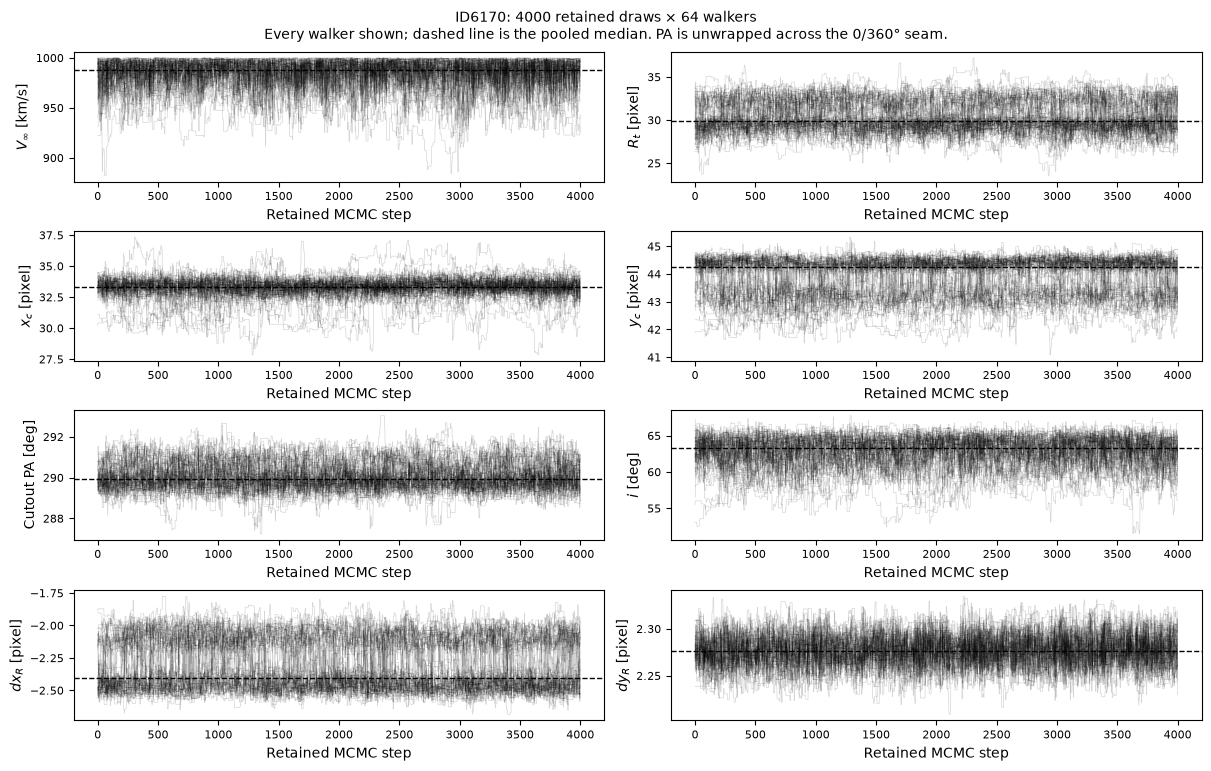

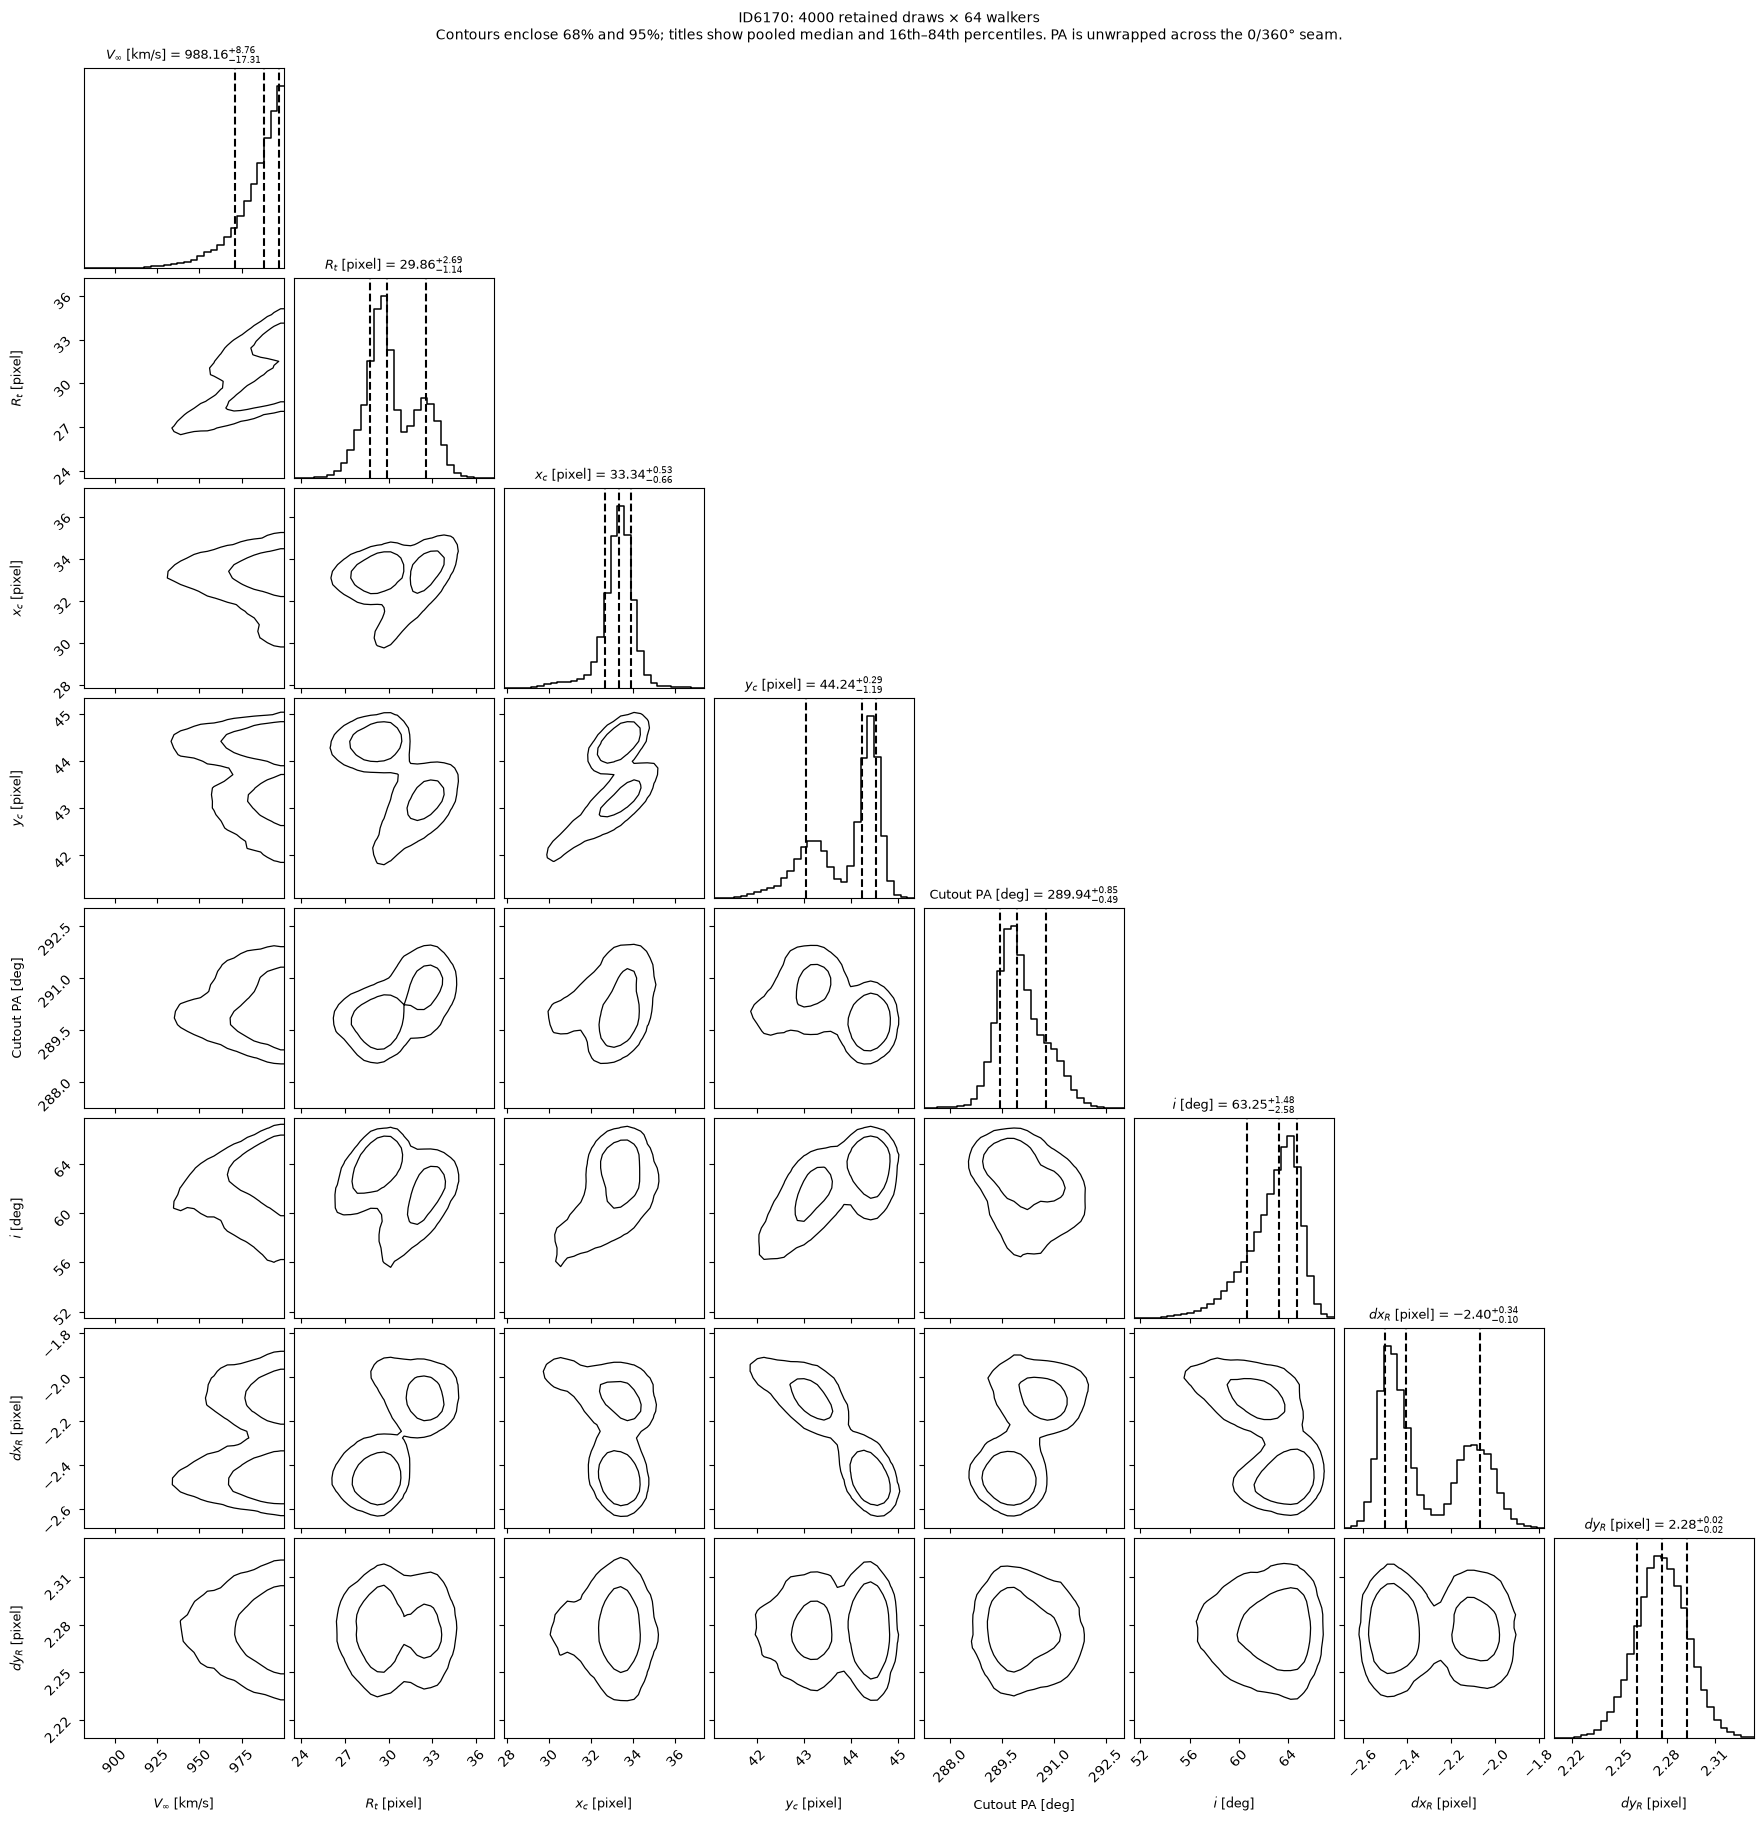

In [5]:
# To view an earlier run without fitting, uncomment and set its exact folder:
# RESULT_DIR = OUTPUT_ROOT / "6170" / "simple_v300_i75"
views = sm.show_results(RESULT_DIR)
display(views["summary"])
for name in ("residuals", "traces", "corner"):
    display(views[name])
    plt.close(views[name])

## What is different from the larger workflow?

| | This notebook | Existing `dingo_runs` workflow |
|---|---|---|
| Gas/velocity model | Original R/C rectification and arctangent disk | Same underlying model |
| Starting fit | Your explicit V, i and geometry, then one optional local fit | Broad candidate search, local refinements and a finite-radius velocity scan |
| Inclination | Explicit Gaussian prior, adjustable here | Usually obtained through the PySersic workflow |
| Noise | Fixed scalar variance; original full-image squared residual | Frozen pixel-dependent variance, effective correlation correction and sampled noise scale |
| Previous results required | None | Manual-start worker normally depends on a parent search |
| Sampling | Existing GPU-batched emcee implementation | Same sampler machinery |

Other priors are explicit in the saved configuration: uniform $V_\infty$ from 0 to `max_velocity`; log-uniform $R_t$ from 0.5 pixels to the cutout half-width; a full-turn uniform orientation; Gaussian center coordinates about the cutout center with 5-pixel width (truncated at ±30 pixels); and Gaussian R registration offsets about zero with 2-pixel width (truncated at ±10 pixels). These are additional assumptions used by both the local fit and MCMC.

The local fit and sampler both use

$$\log P=-\frac{\sum_p(R_p^{\rm rect}-C_p^{\rm rect})^2}{2s^2}+\log p(\mathrm{parameters})+\mathrm{constant},\qquad s^2=A(\sigma_R^2+\sigma_C^2).$$

Here $\sigma_R,\sigma_C$ are fixed background-noise estimates from the input stacks, and $A$ is `noise_correlation_area` (default 1). This preserves the original residual ordering while adding stated priors. **It does not fully propagate coadd/interpolation covariance. Treat the intervals as conditional estimates, not yet validated paper error bars.** It is a transparent baseline for checking the fit and sampler.

Everything for the experiment is saved under `OUTPUT_ROOT/source_ID/run_name/`: `samples.npz`, `prediction.npz`, plots, a parameter table, `config.yaml`, and `run_info.txt` with timestamps, priors, starts, input fingerprints, sampler settings and diagnostics. Checkpoints are in `_checkpoints/`.

To try another source or starting point, duplicate cells 1–4 with a different source ID and `run_name`; each call is independent. To continue an interrupted experiment after restarting the kernel, use `run = sm.open_run(saved_directory)` and `sm.sample(run, warmup=1000, draws=4000, walkers=64, resume=True, progress="notebook")`, keeping the original warmup/walker settings. Increasing `draws` extends the total retained target.